# EJEMPLO COMPLETO DE ANÁLISIS EXPLORATORIO DE LOS DATOS

Vamos a analizar un Dataset con información de las compras realizadas por clientes en una tienda.

Queremos tratar de predecir el gasto mensual de los clientes.

## Importamos librerias

In [2]:
# Importar librerías

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.feature_selection import mutual_info_regression

## Cargar csv

In [3]:
df = pd.read_csv('compras.csv')

## Mostrar DataFrame

In [36]:
df.head()

,Altura_cm,Peso_kg,Gasto_mensual,Años_experiencia,Compras_mes,Región,Nivel_estudios
0,175.0,60.5,1162.0,5.6,3.0,Norte,Básica
1,168.6,68.6,913.0,1.6,4.0,Sur,Grado
2,176.5,76.1,718.0,2.3,2.0,Este,Máster
3,185.2,80.4,1261.0,6.5,2.0,Oeste,Doctorado
4,167.7,55.6,973.0,5.3,3.0,Norte,Básica


## Mostrar Información del Dataset

In [37]:
print('Tipos de datos')
print(df.dtypes)

print('\n')
print('Resumen estructural')
df.info()


Tipos de datos
Altura_cm           float64
Peso_kg             float64
Gasto_mensual       float64
Años_experiencia    float64
Compras_mes         float64
Región               object
Nivel_estudios       object
dtype: object


Resumen estructural
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Altura_cm         240 non-null    float64
 1   Peso_kg           240 non-null    float64
 2   Gasto_mensual     240 non-null    float64
 3   Años_experiencia  240 non-null    float64
 4   Compras_mes       240 non-null    float64
 5   Región            240 non-null    object 
 6   Nivel_estudios    240 non-null    object 
dtypes: float64(5), object(2)
memory usage: 13.3+ KB


## Eliminar Identificadores

In [ ]:
df = df.drop(columns=['ID_cliente'], errors='ignore')

# Mostramos el dataframe sin esa variable
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Altura_cm         240 non-null    float64
 1   Peso_kg           240 non-null    float64
 2   Gasto_mensual     240 non-null    float64
 3   Años_experiencia  240 non-null    float64
 4   Compras_mes       240 non-null    float64
 5   Región            240 non-null    object 
 6   Nivel_estudios    240 non-null    object 
dtypes: float64(5), object(2)
memory usage: 13.3+ KB


## Analizar las Distribuciones

In [39]:
print('\n')
print('Estadisticas descriptivas')
df.describe(include='all')



Estadisticas descriptivas


,Altura_cm,Peso_kg,Gasto_mensual,Años_experiencia,Compras_mes,Región,Nivel_estudios
count,240.000000,240.000000,240.000000,240.000000,240.000000,240,240
unique,NaN,NaN,NaN,NaN,NaN,4,4
top,NaN,NaN,NaN,NaN,NaN,Norte,Básica
freq,NaN,NaN,NaN,NaN,NaN,60,60
mean,169.975417,70.427917,1180.958333,5.245833,3.000000,NaN,NaN
std,9.706670,11.880050,299.855039,1.892195,1.649141,NaN,NaN
min,143.800000,31.100000,391.000000,0.600000,0.000000,NaN,NaN
25%,163.150000,62.425000,972.500000,3.900000,2.000000,NaN,NaN
50%,170.600000,70.150000,1181.500000,5.350000,3.000000,NaN,NaN
75%,175.950000,78.200000,1379.000000,6.400000,4.000000,NaN,NaN


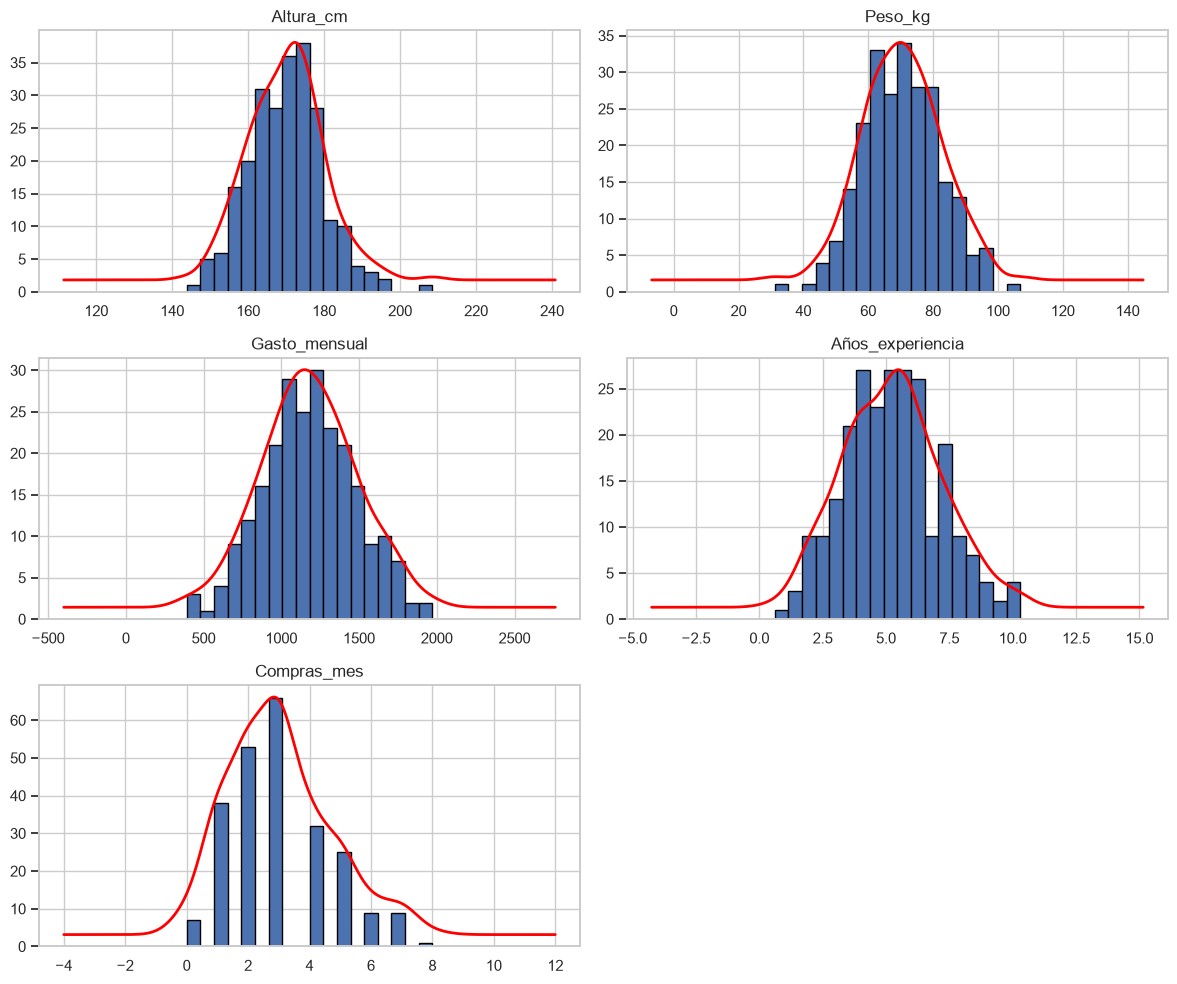

In [20]:
# Histogramas de variables numéricas

# Creamos la cuadrícula de subgráficos primero
axes = df.hist(bins=18, edgecolor='black', figsize=(12, 10))

# Iteramos sobre cada eje para añadirle su curva de densidad
for ax in axes.flatten():
    # Verificamos si el eje tiene datos pintados (por si la cuadrícula es más grande que el nº de columnas)
    if len(ax.get_lines()) == 0 and len(ax.patches) > 0:
        # Creamos un segundo eje Y que comparta el eje X para la curva de densidad
        ax_twin = ax.twinx()
        
        # Buscamos el nombre de la columna correspondiente a ese gráfico por su título
        col_name = ax.get_title()
        
        # Dibujamos la curva de densidad en el eje secundario
        df[col_name].plot(kind='kde', ax=ax_twin, color='red', linewidth=2)
        
        # Opcional: Quitar los ticks del eje Y secundario para que no ensucien el gráfico
        ax_twin.get_yaxis().set_visible(False)

plt.tight_layout()
plt.show()

Otra forma de visualizar la distribución de una variable es a través de un boxplot

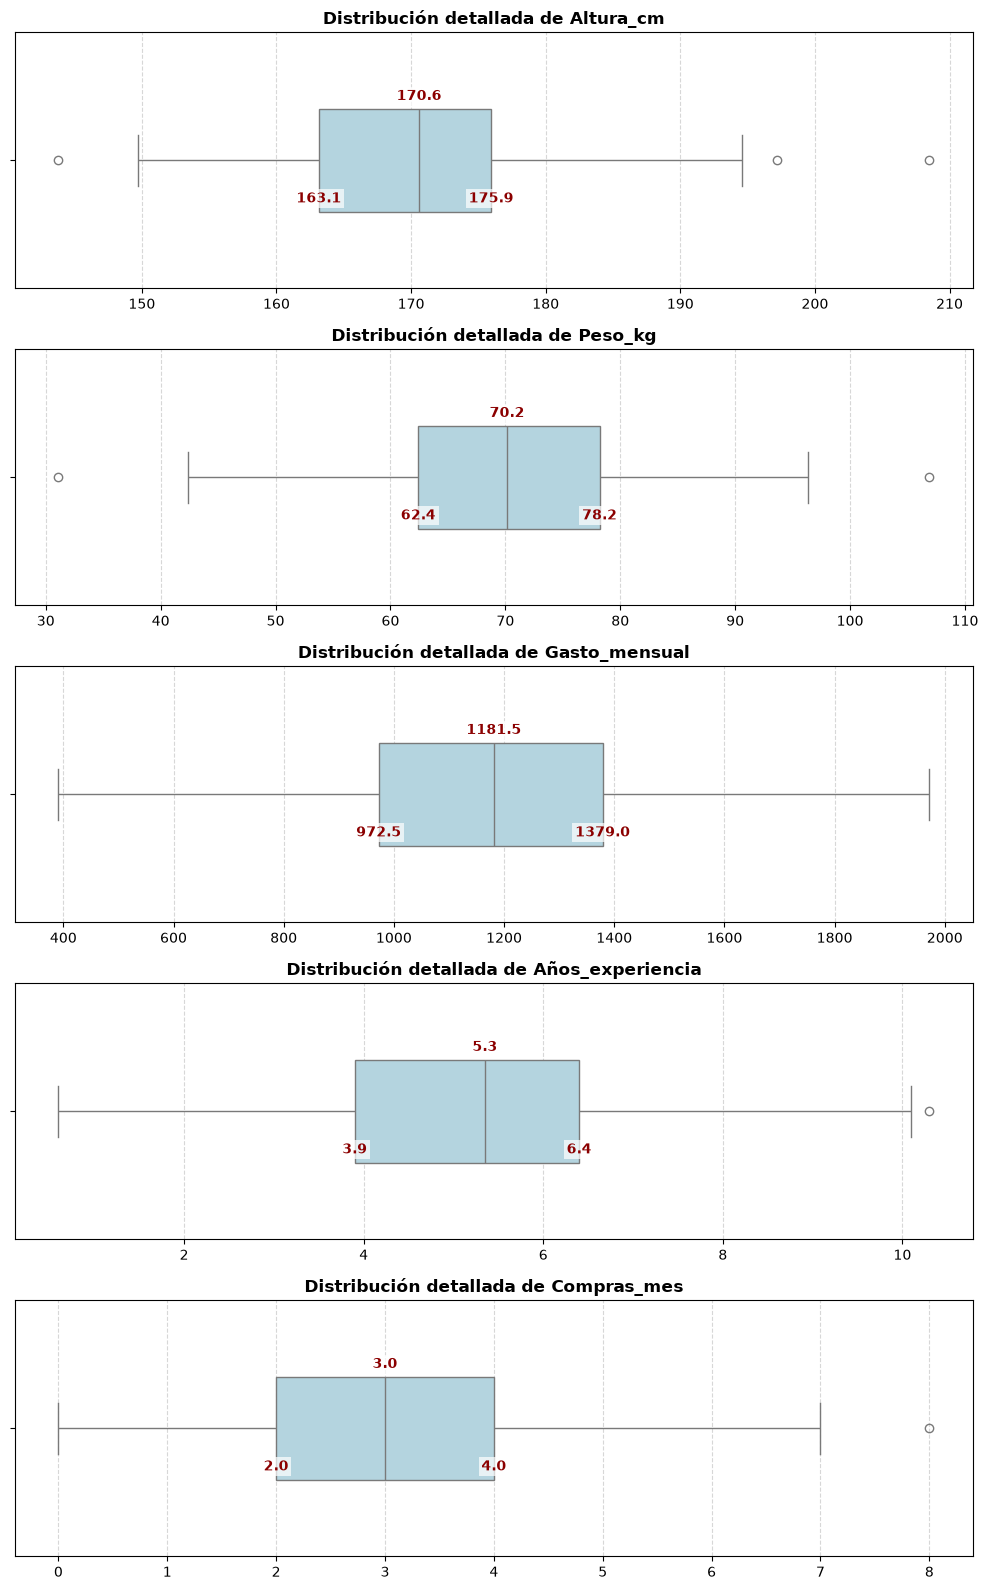

In [41]:
# 1. Instanciar las variables
variables_num = ['Altura_cm', 'Peso_kg', 'Gasto_mensual', 'Años_experiencia', 'Compras_mes']

# 2. Configuración de la cuadrícula (Horizontal para mejor lectura de las líneas)
fig, axes = plt.subplots(nrows=5, ncols=1, figsize=(10, 16)) # 5 filas, 1 columna

# Función para calcular y pintar los cuartiles numéricos
def agregar_valores_boxplot(ax, datos, orientacion='h'):
    # Calcular los valores reales
    q1 = np.percentile(datos, 25)
    mediana = np.percentile(datos, 50)
    q3 = np.percentile(datos, 75)
    
    # Lista de valores a mostrar
    valores = {'Q1': q1, 'Mediana': mediana, 'Q3': q3}
    
    # Pintar el texto sobre el gráfico
    for etiqueta, valor in valores.items():
        # Desplazamiento del texto para que no pise la línea
        offset = 0.15 if etiqueta != 'Mediana' else -0.25 
        
        ax.text(
            x=valor, 
            y=offset, 
            s=f"{valor:.1f}", # Formato con 1 decimal
            ha='center', 
            va='center', 
            fontweight='bold', 
            color='darkred',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', pad=2)
        )

# 3. Dibujar cada gráfico de forma individual
for i, col in enumerate(variables_num):
    # Usamos x=col para que sea horizontal, facilitando ver la escala del cuartil
    sns.boxplot(data=df, x=col, ax=axes[i], color='lightblue', width=0.4)
    
    # Aplicar la función para escribir los números de los cuartiles
    agregar_valores_boxplot(axes[i], df[col].dropna())
    
    # Ajustes estéticos para que se vea limpio
    axes[i].set_title(f'Distribución detallada de {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].grid(axis='x', linestyle='--', alpha=0.5) # Líneas de guía de fondo

plt.tight_layout()
plt.show()

### Comentarios del análisis sobre las distribuciones


En los histogramas vemos que todas las variables numéricas tienen una forma bastante parecida a una campana de Gauss, es decir, se acercan a una distribución normal. Hay algún sesgo pequeño, sobre todo en Compras_mes, que tiene la cola un poco más larga hacia la derecha (tiene sentido, porque es un número de compras y no puede bajar de 0).

Esto quiere decir que los valores del centro son los que más se repiten y que, cuanto más nos alejamos hacia los extremos, menos datos encontramos.

Por lo tanto, los datos están bastante equilibrados y no hay nada raro en cómo se reparten.

## Correlaciones con la variable objetivo

Asumimos que la variable objetivo es Gasto_mensual

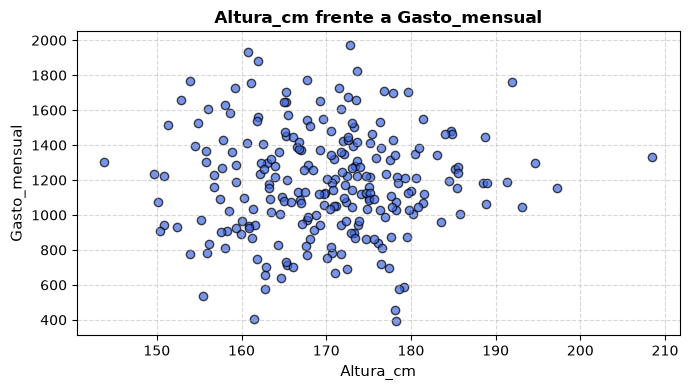

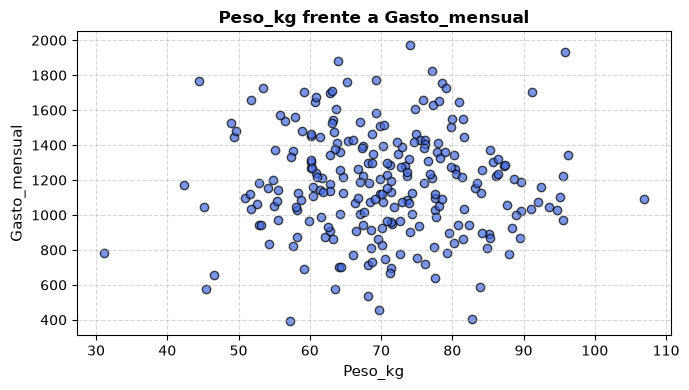

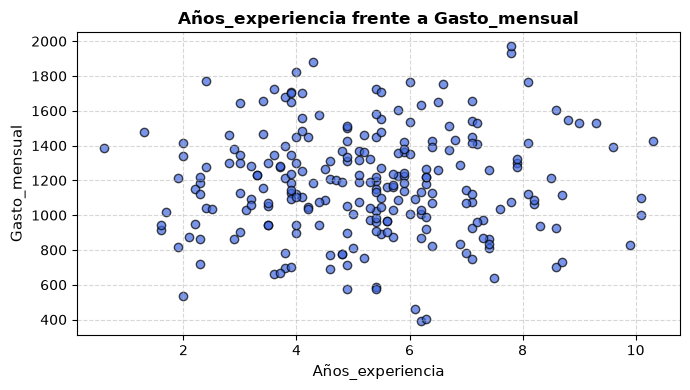

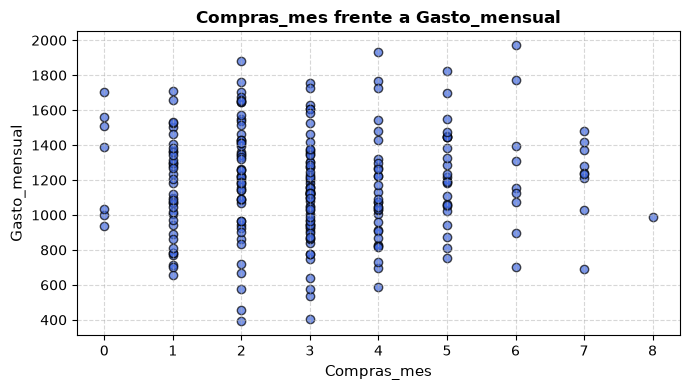

In [42]:
variable_objetivo = 'Gasto_mensual'

# Creamos la lista con las variables que quieres contrastar (excluyendo el propio gasto)
variables_a_graficar = ['Altura_cm', 'Peso_kg', 'Años_experiencia', 'Compras_mes']

# 2. El bucle que genera los gráficos uno a uno
for var in variables_a_graficar:
    plt.figure(figsize=(7, 4)) # Crea una ventana nueva para cada gráfico
    
    # Graficamos la variable actual en el eje X y el objetivo en el eje Y
    plt.scatter(df[var], df[variable_objetivo], alpha=0.7, color='royalblue', edgecolor='k')
    
    # Etiquetas dinámicas según la variable del bucle
    plt.xlabel(var, fontsize=11)
    plt.ylabel(variable_objetivo, fontsize=11)
    plt.title(f'{var} frente a {variable_objetivo}', fontsize=12, fontweight='bold')
    
    plt.grid(True, linestyle='--', alpha=0.5) # Un fondo limpio para seguir los puntos
    plt.tight_layout()
    plt.show() # Muestra el gráfico actual y se detiene hasta que lo cierres/pases al siguiente

### Análisis de las Correlaciones

En los gráficos de dispersión no se ve ninguna correlación con Gasto_mensual, ni positiva ni negativa. Los puntos salen repartidos por todo el gráfico sin seguir ninguna línea ni tendencia.

Con esto podemos decir que ninguna de estas variables, por sí sola, nos ayuda a explicar cuánto gasta un cliente al mes.

## Representación Gráfica de las Correlaciones

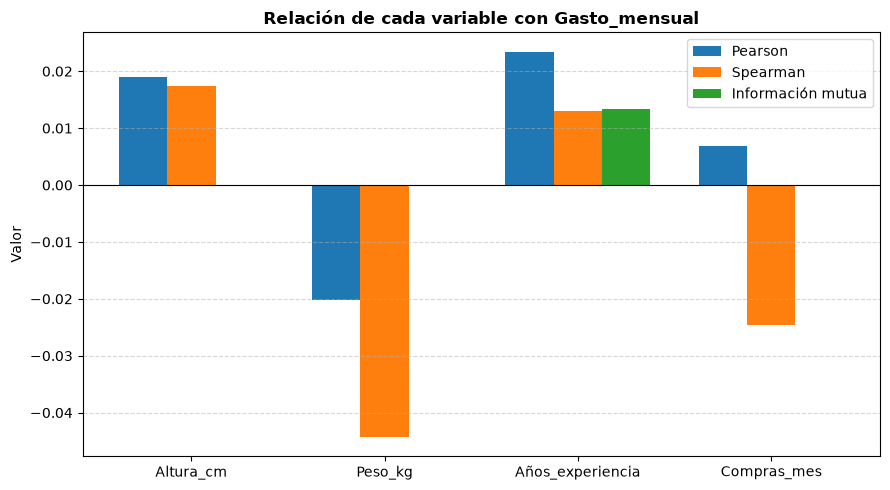

In [43]:
# Comparamos tres formas de medir la relación de cada variable con Gasto_mensual
pearson = df[variables_a_graficar].corrwith(df[variable_objetivo], method='pearson')
spearman = df[variables_a_graficar].corrwith(df[variable_objetivo], method='spearman')

# La información mutua también pilla relaciones no lineales (siempre sale >= 0)
info_mutua = mutual_info_regression(df[variables_a_graficar], df[variable_objetivo], random_state=42)

x = np.arange(len(variables_a_graficar))
ancho = 0.25  # ancho de cada barra

plt.figure(figsize=(9, 5))
plt.bar(x - ancho, pearson, ancho, label='Pearson')
plt.bar(x, spearman, ancho, label='Spearman')
plt.bar(x + ancho, info_mutua, ancho, label='Información mutua')

plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(x, variables_a_graficar)
plt.ylabel('Valor')
plt.title(f'Relación de cada variable con {variable_objetivo}', fontsize=12, fontweight='bold')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Análisis de la representación Gráfica de la Correlación

Los valores de Pearson y de Spearman son casi iguales, así que no parece que haya relaciones no lineales que se le escapen a Pearson. La información mutua lo confirma, porque sale 0 o prácticamente 0 en todas las variables.

Además, todas las barras son muy pequeñas (ninguna pasa de 0,05), por lo que ninguna variable tiene relación con Gasto_mensual.

## Balanceo de las Variables Categóricas

Para variables categóricas

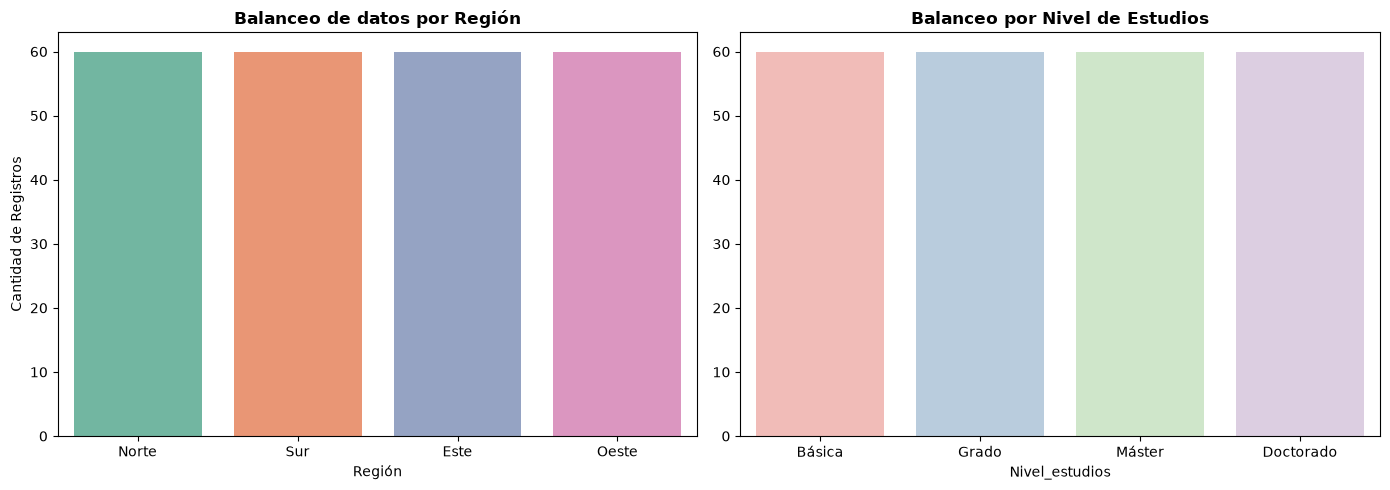

In [44]:
# Creamos una cuadrícula para las 2 variables categóricas
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico para Región
sns.countplot(data=df, x='Región', ax=axes[0], palette='Set2', hue='Región', legend=False)
axes[0].set_title('Balanceo de datos por Región', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Cantidad de Registros')

# Gráfico para Nivel de estudios
sns.countplot(data=df, x='Nivel_estudios', ax=axes[1], palette='Pastel1', hue='Nivel_estudios', legend=False)
axes[1].set_title('Balanceo por Nivel de Estudios', fontsize=12, fontweight='bold')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

### Comentarios sobre el balanceo de Variables Categóricas

Las dos variables categóricas están totalmente balanceadas: cada región (Norte, Sur, Este y Oeste) y cada nivel de estudios (Básica, Grado, Máster y Doctorado) tiene exactamente 60 registros de los 240 que hay. Por eso todas las barras del gráfico tienen la misma altura.

Es algo bastante raro en datos reales. Aun así, es bueno para el análisis, porque ninguna categoría tiene más peso que otra y no hace falta balancear nada.

## Outliers - Boxplots y Número de Outliers

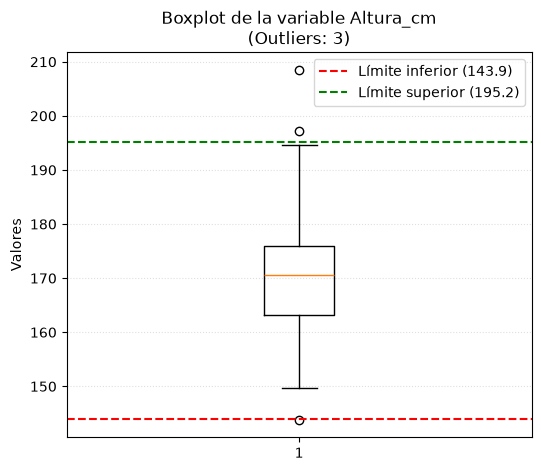

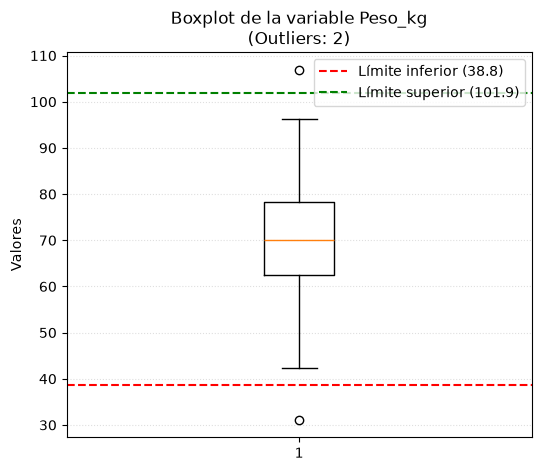

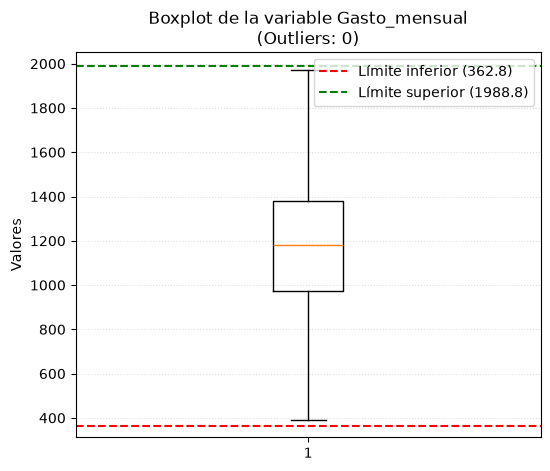

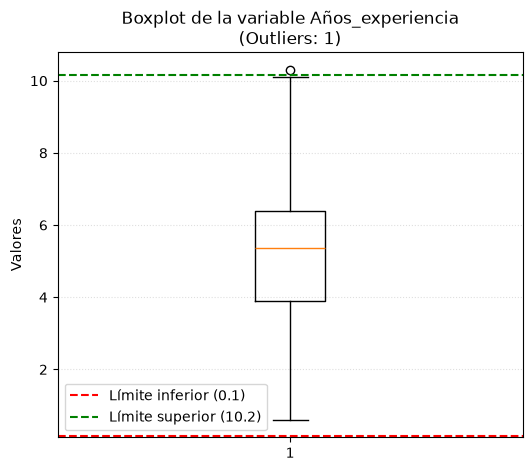

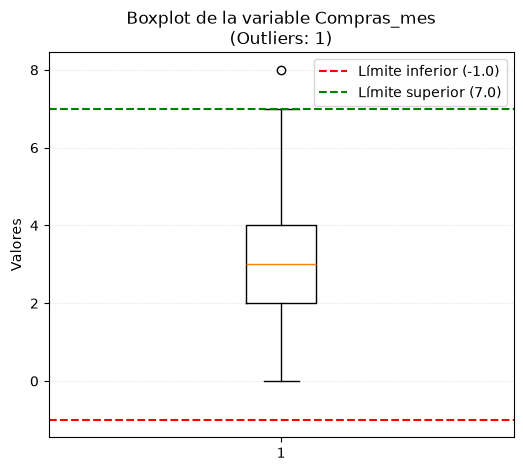

In [45]:
# Selecciona automáticamente las columnas numéricas
columnas_numericas = df.select_dtypes(include="number").columns

for col in columnas_numericas:
  # 1. Calcular cuartiles, IQR y límites de outliers
  q1 = df[col].quantile(0.25)
  q3 = df[col].quantile(0.75)
  iqr = q3 - q1

  limite_inferior = q1 - 1.5 * iqr
  limite_superior = q3 + 1.5 * iqr

  # Contar outliers reales
  n_outliers = (
      (df[col] < limite_inferior) | (df[col] > limite_superior)
  ).sum()

  # 2. Configurar el gráfico
  plt.figure(figsize=(6, 5))
  plt.boxplot(df[col])

  # Pintamos los dos límites para ver a partir de dónde se considera outlier
  plt.axhline(limite_inferior, color="red", linestyle="--", label=f"Límite inferior ({limite_inferior:.1f})")
  plt.axhline(limite_superior, color="green", linestyle="--", label=f"Límite superior ({limite_superior:.1f})")

  # Configuración visual, título y leyenda
  plt.ylabel("Valores")
  plt.title(f"Boxplot de la variable {col}\n(Outliers: {n_outliers})")
  plt.grid(axis="y", linestyle=":", alpha=0.4)

  # Muestra la leyenda solo con los dos límites numéricos
  plt.legend(loc="best")

  plt.show()

### Comentarios sobre Outliers

En los boxplots vemos que hay muy pocos outliers, entre 0 y 3 por variable de un total de 240 datos. Casi todos están por encima del límite superior, o sea, son valores más altos de lo normal.

En variables como Altura_cm o Años_experiencia la mediana (la línea naranja) está un poco más cerca del tercer cuartil.

Como son tan pocos, he decidido no eliminarlos, ya que no deberían afectar mucho al análisis.

## División de datos

In [22]:
# 1. Lista de las variables numéricas
variables_num = [
    "Altura_cm",
    "Peso_kg",
    "Gasto_mensual",
    "Años_experiencia",
    "Compras_mes",
]

# 2. Crear una nueva columna de tramos para cada variable numérica
for col in variables_num:
  df[f"{col}_tramo"] = pd.qcut(
      df[col],
      q=4,
      labels=["Bajo", "Medio-Bajo", "Medio-Alto", "Alto"],
      duplicates="drop",  # Evita errores si hay muchos valores repetidos (ej. en Compras_mes)
  )

# Ver cómo quedan las nuevas columnas creadas
columnas_resultado = [col for col in df.columns if "_tramo" in col]
print(df[columnas_resultado].head())

  Altura_cm_tramo Peso_kg_tramo Gasto_mensual_tramo Años_experiencia_tramo  \
0      Medio-Alto          Bajo          Medio-Bajo             Medio-Alto   
1      Medio-Bajo    Medio-Bajo                Bajo                   Bajo   
2            Alto    Medio-Alto                Bajo                   Bajo   
3            Alto          Alto          Medio-Alto                   Alto   
4      Medio-Bajo          Bajo          Medio-Bajo             Medio-Bajo   

  Compras_mes_tramo  
0        Medio-Bajo  
1        Medio-Alto  
2              Bajo  
3              Bajo  
4        Medio-Bajo  


## Separación columnas por tipo de datos

In [47]:
# Separar nombres de columnas
columnas_numericas = df.select_dtypes(include="number").columns.tolist()
columnas_categoricas = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numéricas:", columnas_numericas)

print("Categóricas:", columnas_categoricas)

Numéricas: ['Altura_cm', 'Peso_kg', 'Gasto_mensual', 'Años_experiencia', 'Compras_mes']
Categóricas: ['Región', 'Nivel_estudios', 'Altura_cm_tramo', 'Peso_kg_tramo', 'Gasto_mensual_tramo', 'Años_experiencia_tramo', 'Compras_mes_tramo']


## Encoders

Usaremos dos encoders distintos:

#### - OrdinalEncoder

Se usa cuando el texto tiene un orden lógico (variables ordinales). Asigna un número entero consecutivo (0, 1, 2, 3...) según la jerarquía que le indiquemos. Es parecido al LabelEncoder, pero este último ordena las categorías alfabéticamente.

#### - OneHotEncoder

Se usa cuando las categorías no tienen ningún orden ni jerarquía entre sí

In [48]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

# 1. Aplicar OrdinalEncoder a 'Nivel_estudios' indicando el orden a mano
# (con LabelEncoder salía alfabético y Doctorado quedaba por debajo de Grado)
oe = OrdinalEncoder(categories=[["Básica", "Grado", "Máster", "Doctorado"]])
df["Nivel_estudios_encoded"] = oe.fit_transform(df[["Nivel_estudios"]]).ravel()

# 2. Aplicar OneHotEncoder a 'Región'
ohe = OneHotEncoder(sparse_output=False, drop="first")  # drop='first' evita redundancia
region_encoded = ohe.fit_transform(df[["Región"]])

# Convertir el resultado del OneHotEncoder en un DataFrame con nombres limpios
df_region_ohe = pd.DataFrame(
    region_encoded, columns=ohe.get_feature_names_out(["Región"])
)

# 3. Añadimos las columnas nuevas al df para seguir usándolas en lo que queda
df = pd.concat([df, df_region_ohe], axis=1)

# Ver el resultado transformado
print(df.head())

   Altura_cm  Peso_kg  Gasto_mensual  Años_experiencia  Compras_mes Región  \
0      175.0     60.5         1162.0               5.6          3.0  Norte   
1      168.6     68.6          913.0               1.6          4.0    Sur   
2      176.5     76.1          718.0               2.3          2.0   Este   
3      185.2     80.4         1261.0               6.5          2.0  Oeste   
4      167.7     55.6          973.0               5.3          3.0  Norte   

  Nivel_estudios Altura_cm_tramo Peso_kg_tramo Gasto_mensual_tramo  \
0         Básica      Medio-Alto          Bajo          Medio-Bajo   
1          Grado      Medio-Bajo    Medio-Bajo                Bajo   
2         Máster            Alto    Medio-Alto                Bajo   
3      Doctorado            Alto          Alto          Medio-Alto   
4         Básica      Medio-Bajo          Bajo          Medio-Bajo   

  Años_experiencia_tramo Compras_mes_tramo  Nivel_estudios_encoded  \
0             Medio-Alto        Medio-Ba

### Comentarios sobre Encoders

Al principio pensaba que era mejor usar solo LabelEncoder, porque no crea columnas nuevas y el dataset queda más limpio. Pero en realidad depende del tipo de variable:

- LabelEncoder cambia cada categoría por un número en la misma columna. Para Nivel_estudios está bien, porque sí hay un orden (Básica < Grado < Máster < Doctorado). El problema es que asigna los números por orden alfabético, así que Doctorado acaba antes que Grado. Por eso al final he usado OrdinalEncoder, que deja indicar el orden a mano.
- OneHotEncoder crea una columna por cada categoría. Genera más columnas, pero para Región es lo correcto. Si pusiéramos Norte = 0, Sur = 1, Este = 2 y Oeste = 3, el modelo pensaría que Oeste es "mayor" que Norte, y eso no tiene sentido.

Así que no se trata de cuál deja el dataset más limpio, sino de usar cada uno según la variable.

## Correlaciones del Conjunto de Entrenamiento

### Correlaciones

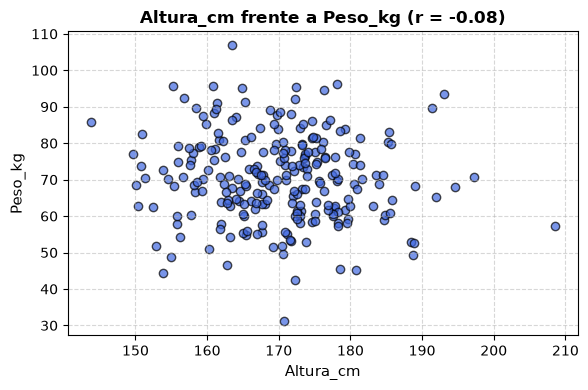

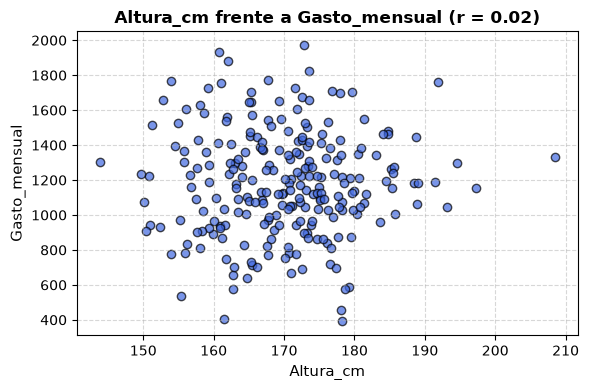

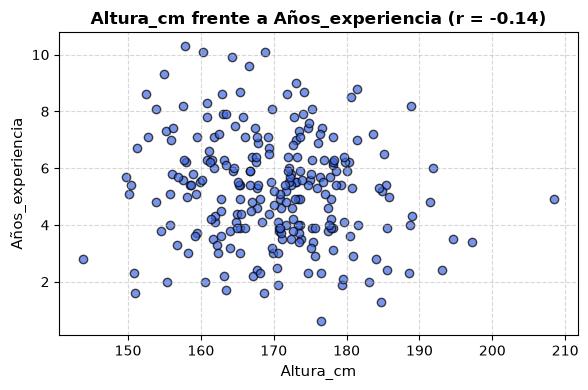

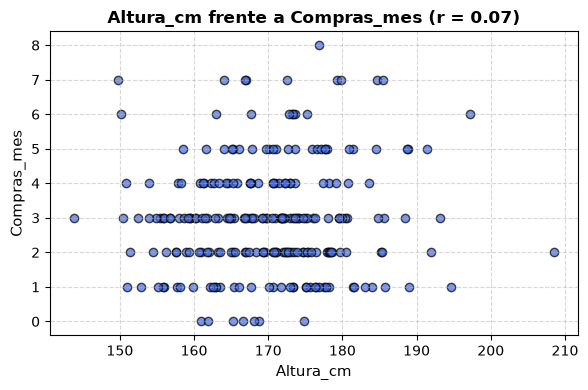

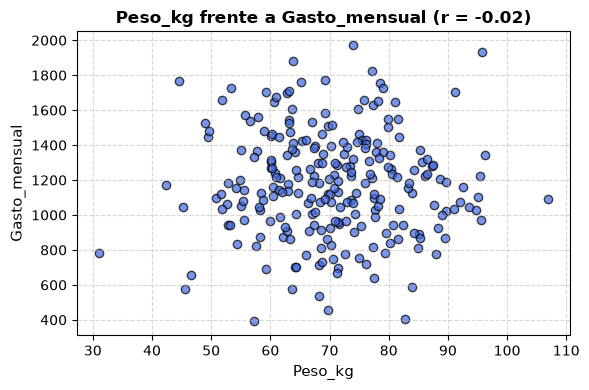

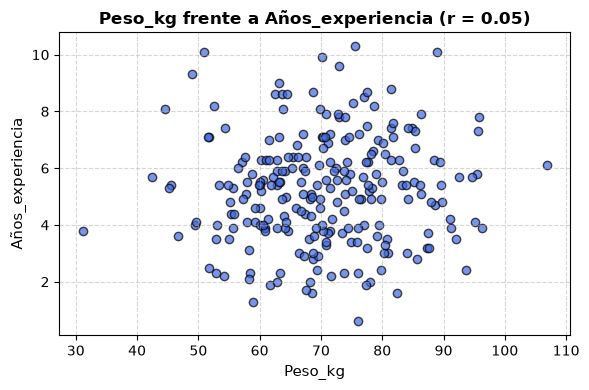

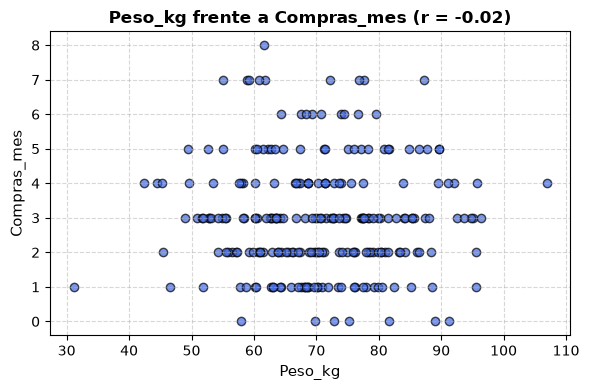

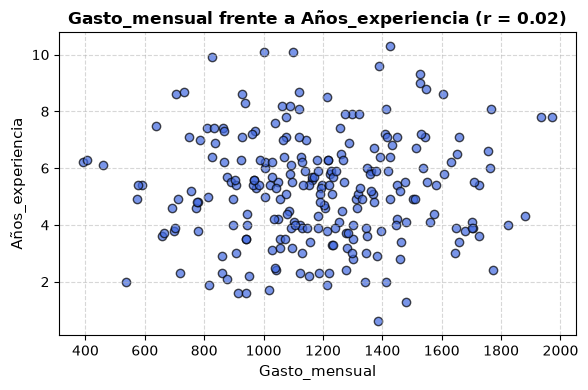

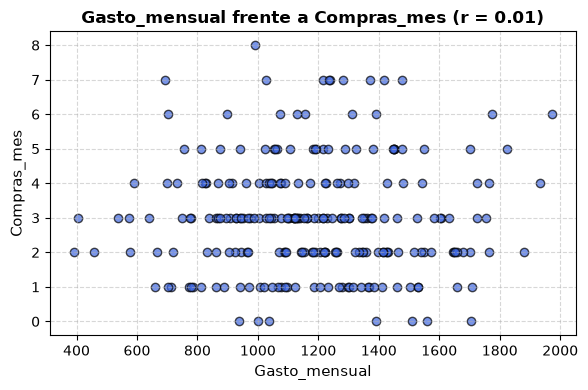

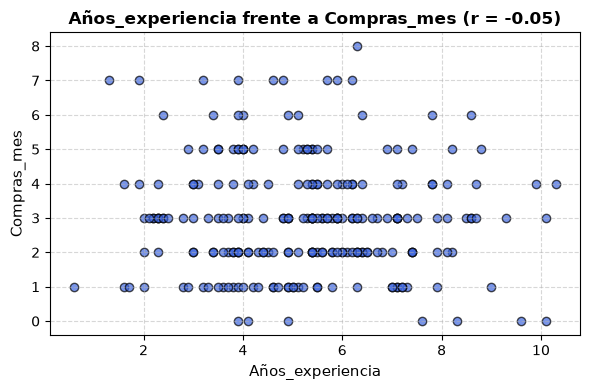

In [49]:
from itertools import combinations

# Un gráfico de dispersión por cada pareja de variables numéricas (sin repetir)
for var_x, var_y in combinations(variables_num, 2):
    coef = df[var_x].corr(df[var_y])  # para poner el valor de r en el título

    plt.figure(figsize=(6, 4))
    plt.scatter(df[var_x], df[var_y], alpha=0.7, color='royalblue', edgecolor='k')

    plt.xlabel(var_x, fontsize=11)
    plt.ylabel(var_y, fontsize=11)
    plt.title(f'{var_x} frente a {var_y} (r = {coef:.2f})', fontsize=12, fontweight='bold')

    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

### Matriz de Correlaciones

Text(0.5, 1.0, 'Correlación de Pearson (Lineal)')

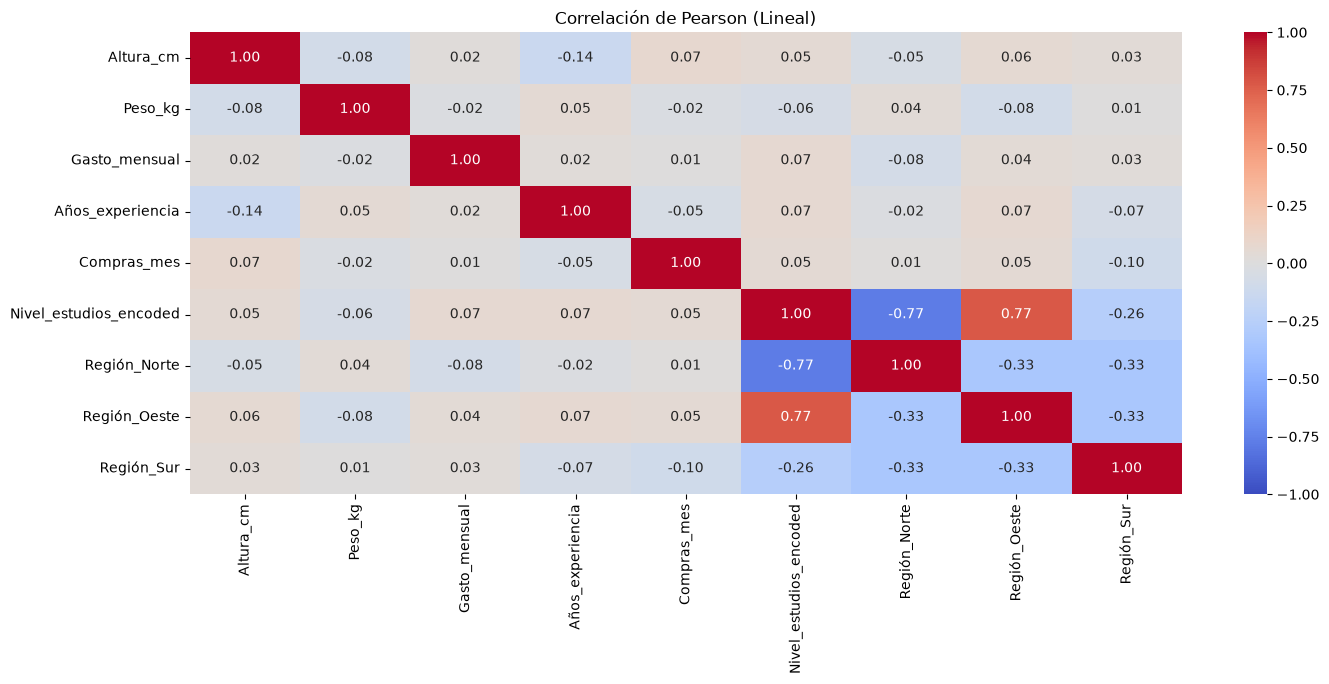

In [50]:
# Correlación de Pearson
correlacion_pearson = df.corr(method='pearson', numeric_only=True)

fig, ax = plt.subplots(1, 1, figsize=(16, 6))

# Mapa de calor para Pearson
sns.heatmap(correlacion_pearson, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlación de Pearson (Lineal)')

Text(0.5, 1.0, 'Correlación de Spearman (Rangos)')

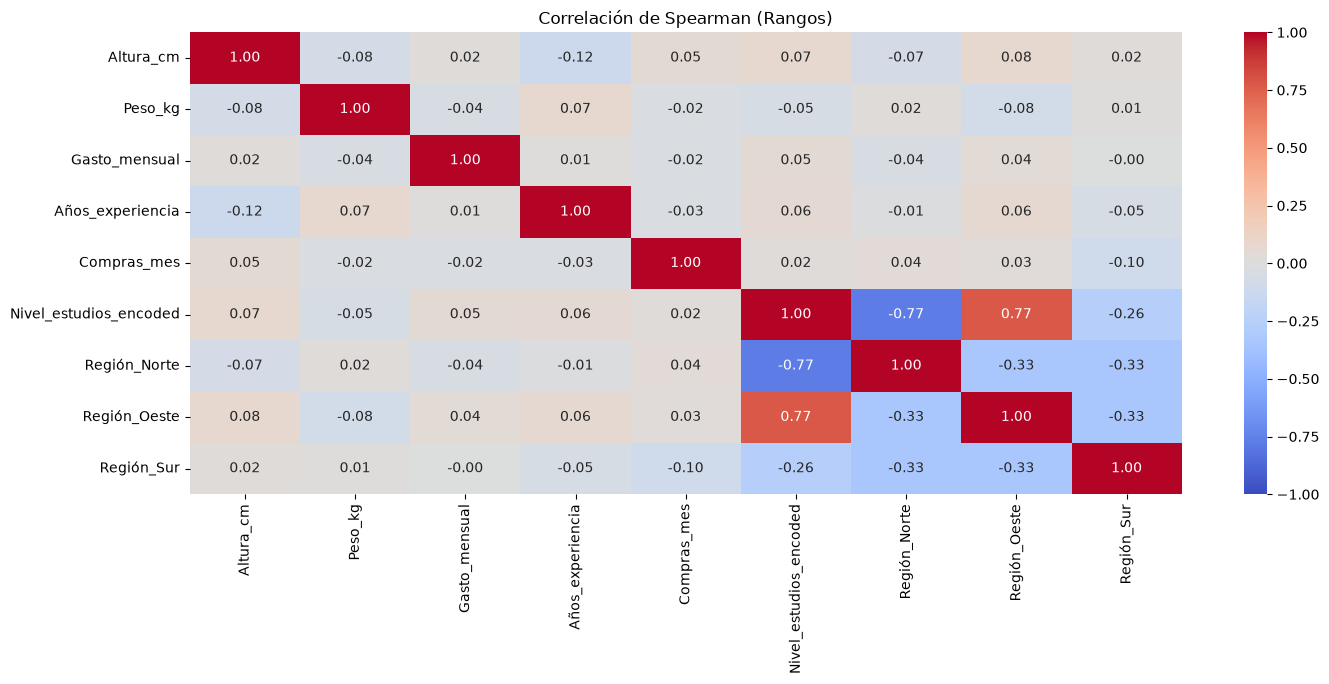

In [51]:
# Correlación Spearman
correlacion_spearman = df.corr(method='spearman', numeric_only=True)

fig, ax = plt.subplots(1, 1, figsize=(16, 6))
sns.heatmap(correlacion_spearman, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1, ax=ax)
ax.set_title('Correlación de Spearman (Rangos)')

### Evaluación de las correlaciones y la matriz de correlación

Como ya comenté antes, las variables numéricas no tienen ninguna relación clara entre ellas. Tanto en Pearson como en Spearman todos los valores están cerca de 0; el más alto es -0,14, entre Altura_cm y Años_experiencia, y aun así es muy bajo.

Lo que sí llama la atención en la matriz es que Nivel_estudios_encoded tiene una correlación de 0,77 (o -0,77) con algunas columnas de Región. Revisando los datos, he visto que cada región tiene un único nivel de estudios: Norte siempre es Básica, Sur es Grado, Este es Máster y Oeste es Doctorado. Es decir, las dos variables dan exactamente la misma información, y por eso también salían igual de balanceadas. Para un modelo bastaría con quedarse con una de las dos. Las correlaciones de -0,33 entre las columnas de Región son normales, porque salen todas de la misma variable.

Por un lado es bueno que no haya más variables que repitan información. Por otro, como ninguna se relaciona con Gasto_mensual, va a ser complicado predecirlo con estos datos.

## Normalización y escalado

Para la estandarización de las variables utilizaremos el 'StandardScaler'

- media = 0
- desviación típica = 1

Es especialmente útil para algoritmos sensibles a la escala.

In [52]:
variables_escalado = [
    "Altura_cm",
    "Peso_kg",
    "Gasto_mensual",
    "Años_experiencia",
    "Compras_mes"
]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    df[variables_escalado]
)

df_scaled = pd.DataFrame(
    X_scaled,
    columns=variables_escalado
)

df_scaled.head()

,Altura_cm,Peso_kg,Gasto_mensual,Años_experiencia,Compras_mes
0,0.518724,-0.837426,-0.063357,0.187564,0.000000
1,-0.141994,-0.154186,-0.895494,-1.930802,0.607644
2,0.673580,0.478444,-1.547167,-1.560088,-0.607644
3,1.571744,0.841152,0.267492,0.664196,-0.607644
4,-0.234908,-1.250744,-0.694979,0.028686,0.000000


Para normalizar las variables utilizaremos 'Min-Max'

In [53]:
minmax = MinMaxScaler()

X_minmax = minmax.fit_transform(
    df[variables_escalado]
)

df_minmax = pd.DataFrame(
    X_minmax,
    columns=variables_escalado
)

df_minmax.head()

,Altura_cm,Peso_kg,Gasto_mensual,Años_experiencia,Compras_mes
0,0.482226,0.387863,0.487666,0.515464,0.375
1,0.383308,0.494723,0.330171,0.103093,0.500
2,0.505410,0.593668,0.206831,0.175258,0.250
3,0.639876,0.650396,0.550285,0.608247,0.250
4,0.369397,0.323219,0.368121,0.484536,0.375


# PIPELINES

Aquí juntamos en un solo bloque de código todo lo que hemos hecho en el cuaderno, desde cargar los datos hasta normalizarlos. Para ello usamos Pipeline y ColumnTransformer de scikit-learn, que permiten encadenar los pasos y aplicarlos todos de una vez.

Los pasos son:

1. Importar las librerías.
2. Cargar el csv.
3. Quitar el ID del cliente.
4. Separar las variables en numéricas, ordinales y nominales.
5. Crear el preprocesador (encoders y escalado).
6. Crear dos pipelines: uno con StandardScaler y otro con MinMaxScaler.
7. Aplicarlos a los datos.
8. Comprobar que el escalado ha salido bien.

No he metido los gráficos, las correlaciones ni los tramos porque son parte del análisis y no cambian los datos. Además, en vez de LabelEncoder he usado OrdinalEncoder, porque se puede meter dentro del pipeline y me deja poner el orden de los estudios.

In [54]:
# 1. Librerías
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder, StandardScaler

# 2. Cargamos los datos del csv (sin tocar el archivo original)
datos = pd.read_csv('compras.csv')

# 3. Quitamos el ID del cliente, no sirve para nada en el análisis
# (pongo errors='ignore' porque en el csv actual ya no está esa columna)
datos = datos.drop(columns=['ID_cliente'], errors='ignore')

# 4. Separamos las variables según su tipo
variables_numericas = ['Altura_cm', 'Peso_kg', 'Gasto_mensual', 'Años_experiencia', 'Compras_mes']
variables_ordinales = ['Nivel_estudios']   # tiene orden
variables_nominales = ['Región']           # no tiene orden

# Le indico el orden a mano, si no lo ordena alfabéticamente y Doctorado
# quedaría por debajo de Grado
orden_estudios = [['Básica', 'Grado', 'Máster', 'Doctorado']]

# 5. Preprocesador: a cada grupo de columnas le aplicamos lo suyo
# - numéricas: escalado (le pasamos el que queramos)
# - Nivel_estudios: OrdinalEncoder (0, 1, 2, 3)
# - Región: OneHotEncoder, quitando la primera columna para no repetir info
def crear_preprocesador(escalador):
    return ColumnTransformer(
        transformers=[
            ('numericas', escalador, variables_numericas),
            ('ordinales', OrdinalEncoder(categories=orden_estudios), variables_ordinales),
            ('nominales', OneHotEncoder(drop='first', sparse_output=False), variables_nominales),
        ],
        verbose_feature_names_out=False,  # para que las columnas mantengan su nombre
    ).set_output(transform='pandas')      # así nos devuelve un DataFrame y no un array

# 6. Creamos dos pipelines, uno para estandarizar y otro para normalizar
pipeline_estandarizacion = Pipeline([('preprocesado', crear_preprocesador(StandardScaler()))])
pipeline_normalizacion = Pipeline([('preprocesado', crear_preprocesador(MinMaxScaler()))])

# 7. Los aplicamos a los datos
datos_estandarizados = pipeline_estandarizacion.fit_transform(datos)
datos_normalizados = pipeline_normalizacion.fit_transform(datos)

# 8. Comprobamos que ha funcionado
# Estandarizado -> media 0 y desviación 1
print('Estandarización:')
print(datos_estandarizados[variables_numericas].agg(['mean', 'std']).round(2), '\n')

# Normalizado -> valores entre 0 y 1
print('Normalización:')
print(datos_normalizados[variables_numericas].agg(['min', 'max']).round(2), '\n')

datos_estandarizados.head()

Estandarización:
      Altura_cm  Peso_kg  Gasto_mensual  Años_experiencia  Compras_mes
mean        0.0     -0.0            0.0              -0.0         -0.0
std         1.0      1.0            1.0               1.0          1.0 

Normalización:
     Altura_cm  Peso_kg  Gasto_mensual  Años_experiencia  Compras_mes
min        0.0      0.0            0.0               0.0          0.0
max        1.0      1.0            1.0               1.0          1.0 



,Altura_cm,Peso_kg,Gasto_mensual,Años_experiencia,Compras_mes,Nivel_estudios,Región_Norte,Región_Oeste,Región_Sur
0,0.518724,-0.837426,-0.063357,0.187564,0.000000,0.0,1.0,0.0,0.0
1,-0.141994,-0.154186,-0.895494,-1.930802,0.607644,1.0,0.0,0.0,1.0
2,0.673580,0.478444,-1.547167,-1.560088,-0.607644,2.0,0.0,0.0,0.0
3,1.571744,0.841152,0.267492,0.664196,-0.607644,3.0,0.0,1.0,0.0
4,-0.234908,-1.250744,-0.694979,0.028686,0.000000,0.0,1.0,0.0,0.0
